In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:
np.random.seed(42)

n = 200

study_hours = np.random.uniform(1, 10, n)
attendance = np.random.uniform(50, 100, n)
previous_marks = np.random.uniform(30, 95, n)

noise = np.random.normal(0, 5, n)

final_marks = (
    3 * study_hours
    + 0.2 * attendance
    + 0.5 * previous_marks
    + noise
)

final_marks = np.clip(final_marks, 0, 100)

df = pd.DataFrame({
    "study_hours": study_hours,
    "attendance": attendance,
    "previous_marks": previous_marks,
    "final_marks": final_marks
})

df.to_csv("student_data.csv", index=False)

df.head()


,study_hours,attendance,previous_marks,final_marks
0,4.370861,82.101582,36.703051,45.233137
1,9.556429,54.206998,88.665939,79.879291
2,7.587945,58.081436,62.841404,65.265674
3,6.387926,94.927709,83.719735,74.832977
4,2.404168,80.321453,50.803224,45.910159


In [ ]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (200, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   study_hours     200 non-null    float64
 1   attendance      200 non-null    float64
 2   previous_marks  200 non-null    float64
 3   final_marks     200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB

Statistical Summary:


,study_hours,attendance,previous_marks,final_marks
count,200.000000,200.000000,200.000000,200.000000
mean,5.356056,75.218757,63.843731,62.736304
std,2.654023,14.650060,19.975072,13.699698
min,1.049699,50.253079,30.704447,30.084805
25%,3.057242,63.073125,46.608821,52.739629
50%,5.450376,77.081994,64.150966,61.580516
75%,7.811737,87.109966,82.722468,73.523945
max,9.881982,99.525257,94.981649,95.096594



Missing Values:
study_hours       0
attendance        0
previous_marks    0
final_marks       0
dtype: int64


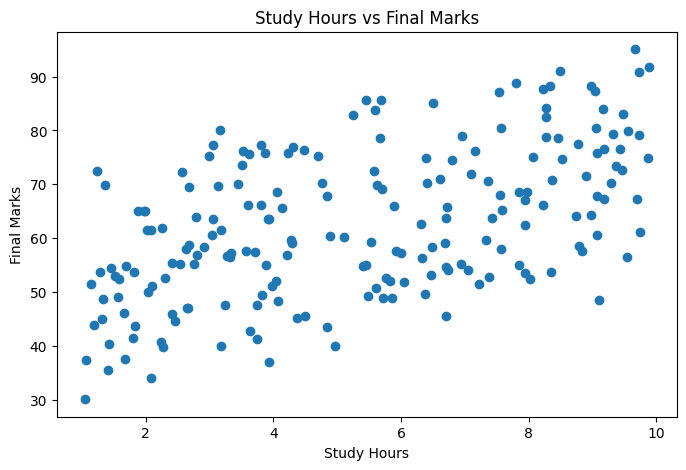

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(df["study_hours"], df["final_marks"])

plt.xlabel("Study Hours")
plt.ylabel("Final Marks")
plt.title("Study Hours vs Final Marks")

plt.show()

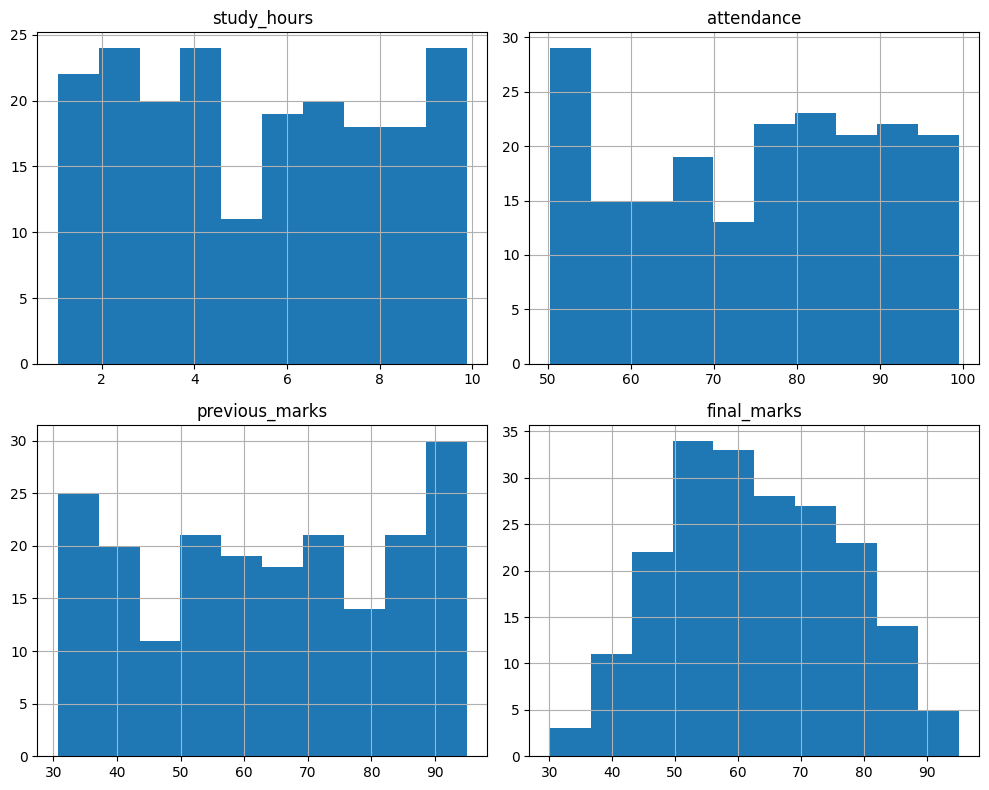

In [ ]:
df[["study_hours", "attendance", "previous_marks", "final_marks"]].hist(
    figsize=(10, 8)
)

plt.tight_layout()
plt.show()

In [ ]:
X = df[["study_hours", "attendance", "previous_marks"]]

y = df["final_marks"]

print("Features:")
display(X.head())

print("Target:")
display(y.head())

Features:


,study_hours,attendance,previous_marks
0,4.370861,82.101582,36.703051
1,9.556429,54.206998,88.665939
2,7.587945,58.081436,62.841404
3,6.387926,94.927709,83.719735
4,2.404168,80.321453,50.803224


Target:


,final_marks
0,45.233137
1,79.879291
2,65.265674
3,74.832977
4,45.910159


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 160
Testing Records: 40


In [ ]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [ ]:
predictions = model.predict(X_test)

results = pd.DataFrame({
    "Actual Marks": y_test.values,
    "Predicted Marks": predictions
})

display(results.head(10))

,Actual Marks,Predicted Marks
0,55.018935,57.406083
1,47.019801,49.949548
2,53.217300,55.615810
3,69.760320,68.263623
4,37.379821,33.465941
5,57.588537,57.649922
6,91.739592,89.289060
7,71.972609,63.964223
8,74.436997,74.831703
9,79.042867,85.934592


In [ ]:
mae = mean_absolute_error(y_test, predictions)

mse = mean_squared_error(y_test, predictions)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, predictions)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 3.5243455162211688
Mean Squared Error: 17.260347579582756
Root Mean Squared Error: 4.154557446898858
R2 Score: 0.9109010356234497


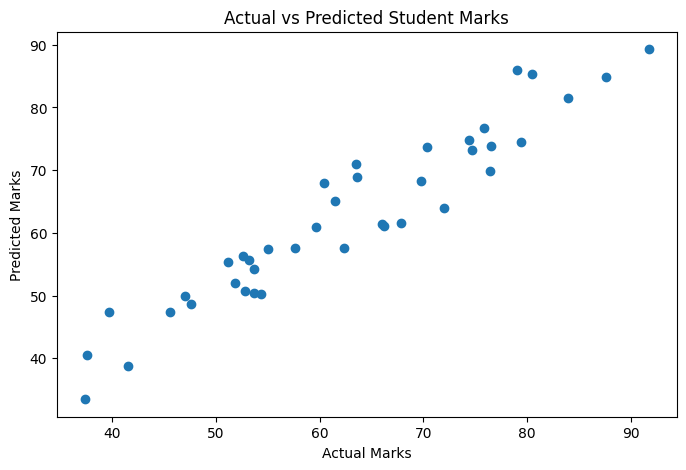

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, predictions)

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")

plt.title("Actual vs Predicted Student Marks")

plt.show()

In [ ]:
joblib.dump(model, "student_performance_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
new_student = pd.DataFrame({
    "study_hours": [6],
    "attendance": [85],
    "previous_marks": [75]
})

predicted_marks = model.predict(new_student)

print("Predicted Final Marks:", round(predicted_marks[0], 2))

Predicted Final Marks: 72.29


In [1]:
import os

print(os.listdir())

['.config', 'sample_data']
